# Proyecto final · 03 · Preparación de los datos

Primera etapa del pipeline: de los archivos oficiales de BEA-2019 a los pares que ve BART y a los conjuntos con que se evalúa. Cada paso aplica una decisión de los notebooks 01 y 02 y se muestra con una oración real.

```mermaid
flowchart LR
    A[M2 + JSON<br/>oficiales] --> B[1 · leer<br/>corpus.leer_m2]
    B --> C[2 · aplicar ediciones<br/>original → corregida]
    C --> D[3 · destokenizar<br/>texto.destokenizar]
    D --> E[4 · filtrar train<br/>sin UNK, sin duplicados]
    D --> F[5 · conjuntos de<br/>evaluación]
    E --> G[6 · BPE de BART<br/>máx. 128]
    E --> H[train.jsonl]
    F --> I[entrada.jsonl<br/>orig.txt · ref.m2]
```

El código vive en `src/` (`corpus.py`, `texto.py`, `preparar.py`, con tests en `tests/`); este notebook lo llama paso a paso y muestra qué hace cada transformación. `make preparar` produce los mismos archivos sin abrir el notebook.

In [1]:
import json
import os
import subprocess
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
import corpus
import preparar
import texto
from graficas import COLOR_CORPUS, NOMBRE_CORPUS, TINTA_SECUNDARIA, aplicar_estilo

CRUDOS, SALIDA, FIG = RAIZ / "datos" / "crudos", RAIZ / "datos" / "procesados" / "entrenamiento", RAIZ / "figuras"
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)
aplicar_estilo()

## 1 · Leer los archivos M2

Cada corpus trae dos archivos por split: el **M2** (oraciones tokenizadas con las ediciones de los anotadores) y el **JSON** (el ensayo completo con la L1, la edad y la nota del autor). Así luce un bloque M2 real, de un hispanohablante en el test de FCE:

- `S` es la oración tal como la escribió el estudiante, separada en tokens.
- Cada `A` es una edición: posición de inicio y fin en tokens, tipo de error, corrección y número de anotador.

In [2]:
oraciones, ediciones = corpus.cargar(CRUDOS)
bloques = preparar.bloques_m2(CRUDOS)
# Comprobación que hace también preparar.py: un bloque M2 por oración, en el mismo orden
assert len(bloques) == len(oraciones)
assert all(b.split("\n")[0][2:] == s for b, s in zip(bloques, oraciones.original))

EJEMPLO = oraciones[oraciones.original.str.startswith("As you know I am in charge")].id.item()
print(bloques[EJEMPLO])
print(f"\n{len(oraciones):,} oraciones · {len(ediciones):,} ediciones (anotador 0)")

S As you know I am in charge for organise the conference in my college . Do not worry if Richard did not left you all the information .
A 3 3|||M:PUNCT|||,|||REQUIRED|||-NONE-|||0
A 7 8|||R:PREP|||of|||REQUIRED|||-NONE-|||0
A 8 9|||R:VERB:FORM|||organising|||REQUIRED|||-NONE-|||0
A 22 23|||R:VERB:FORM|||leave|||REQUIRED|||-NONE-|||0

71,928 oraciones · 123,986 ediciones (anotador 0)


In [3]:
oracion = corpus.leer_m2(bloques[EJEMPLO])[0]
pd.DataFrame([
    {"tokens": f"{e.inicio}–{e.fin}", "original": " ".join(oracion.tokens[e.inicio:e.fin]) or "∅",
     "tipo": e.tipo, "corrección": e.correccion or "∅"}
    for e in oracion.ediciones
])

,tokens,original,tipo,corrección
0,3–3,∅,M:PUNCT,","
1,7–8,for,R:PREP,of
2,8–9,organise,R:VERB:FORM,organising
3,22–23,left,R:VERB:FORM,leave


`corpus.cargar` alinea cada oración con su ensayo del JSON (comparando el texto sin espacios), y así cada oración hereda la L1 del autor. Esa columna es la que después separa a los hispanohablantes:

In [4]:
oraciones.loc[[EJEMPLO], ["id", "corpus", "split", "texto", "autor", "l1", "n_tokens", "n_ediciones"]]

,id,corpus,split,texto,autor,l1,n_tokens,n_ediciones
30631,30631,fce,test,TE4*0100*2001*01#1,TE4*0100*2001*01,es,28,4


## 2 · Aplicar las ediciones: el par original → corregida

`corpus.aplicar_ediciones` aplica las ediciones de derecha a izquierda para que las posiciones de las anteriores no se corran. El resultado es la oración **destino** que BART debe aprender a generar.

In [5]:
corregida = corpus.aplicar_ediciones(oracion.tokens, oracion.ediciones)
print("original :", " ".join(oracion.tokens))
print("corregida:", " ".join(corregida))

original : As you know I am in charge for organise the conference in my college . Do not worry if Richard did not left you all the information .
corregida: As you know , I am in charge of organising the conference in my college . Do not worry if Richard did not leave you all the information .


## 3 · Destokenizar: el texto que ve BART

Los M2 separan la puntuación y las contracciones (`do n't`, `it 's`). BART se preentrenó con texto normal y el usuario de la app escribirá texto normal, así que se entrena con texto natural (decisión T1 del notebook 02: la ida y vuelta es exacta en el 99,34 % de las oraciones). Se conservan las dos versiones, porque ERRANT evalúa sobre los tokens del M2.

In [6]:
o = preparar.marcar(oraciones, ediciones)
pd.DataFrame({
    "tokens del M2": [o.original[EJEMPLO], o.corregida[EJEMPLO]],
    "texto natural (BART)": [o.original_texto[EJEMPLO], o.corregida_texto[EJEMPLO]],
}, index=["original", "corregida"])

,tokens del M2,texto natural (BART)
original,As you know I am in charge for organise the conference in my college . Do not worry if Richard did not left you all the information .,As you know I am in charge for organise the conference in my college. Do not worry if Richard did not left you all the information.
corregida,"As you know , I am in charge of organising the conference in my college . Do not worry if Richard did not leave you all the information .","As you know, I am in charge of organising the conference in my college. Do not worry if Richard did not leave you all the information."


In [7]:
# Las reglas de src/texto.py sobre casos típicos del corpus
casos = ["I do n't know , it 's fine .", 'He said " yes " ( twice ) .', "a well - known fact", "I 'm 25 years old !"]
pd.DataFrame({"tokens": casos, "texto natural": [texto.destokenizar(c.split()) for c in casos]})

,tokens,texto natural
0,"I do n't know , it 's fine .","I don't know, it's fine."
1,"He said "" yes "" ( twice ) .","He said ""yes"" (twice)."
2,a well - known fact,a well-known fact
3,I 'm 25 years old !,I'm 25 years old!


## 4 · Filtrar el entrenamiento

Train = FCE train + W&I train (niveles A, B, C): **62.658 pares**. Se quitan dos grupos y se conserva todo lo demás, incluidas las oraciones sin error (enseñan a no tocar lo que está bien).

### 4a · Pares con `UNK`

`UNK` es una edición que el anotador marcó como errónea pero **no corrigió**: la corrección es el mismo texto. Si BART aprendiera estos pares, aprendería a dejar errores reconocidos tal como están.

In [8]:
for inicio in ["reasently", "If you do , make sure why"]:
    print(bloques[o[o.original.str.startswith(inicio)].id.iloc[0]], "\n")

S reasently
A 0 1|||UNK|||reasently|||REQUIRED|||-NONE-|||0 

S If you do , make sure why you want to earn money .
A 4 6|||UNK|||make sure|||REQUIRED|||-NONE-|||0 



In [9]:
en_train = o.split.eq("train") & o.corpus.isin(["fce", "wi"])
con_unk = o[en_train & o.tiene_unk]
print(f"{len(con_unk):,} pares de train con al menos una edición UNK ({100 * len(con_unk) / en_train.sum():.1f}%)")
solo_unk = ediciones.groupby("id_oracion").tipo.agg(lambda t: t.eq("UNK").all())
print(f"de ellos, {solo_unk.reindex(con_unk.id).sum():,} tienen solo ediciones UNK; el resto mezcla UNK con "
      "correcciones reales y también se excluye, porque su destino sigue teniendo un error")

2,779 pares de train con al menos una edición UNK (4.4%)


de ellos, 638 tienen solo ediciones UNK; el resto mezcla UNK con correcciones reales y también se excluye, porque su destino sigue teniendo un error


### 4b · Pares duplicados

Los duplicados exactos (mismo original y misma corrección) son casi todos fórmulas de carta y la frase con que el examen de FCE pedía empezar la historia. Repetidos cien veces o más, sobrerrepresentarían las oraciones que no necesitan corrección.

In [10]:
sin_unk = o[en_train & ~o.tiene_unk]
repetidos = sin_unk.groupby(["original_texto", "corregida_texto"]).size().sort_values(ascending=False)
print(f"{sin_unk.duplicated(['original_texto', 'corregida_texto']).sum():,} copias sobrantes "
      f"en {(repetidos > 1).sum():,} pares distintos")
repetidos.head(8).rename("veces").reset_index().drop(columns="corregida_texto")

3,625 copias sobrantes en 631 pares distintos


,original_texto,veces
0,"Yours sincerely,",167
1,"Yours faithfully,",166
2,Yours sincerely,166
3,"Dear Kim,",114
4,"Unfortunately, Pat wasn't very good at keeping secrets.",109
5,"Dear Sir,",104
6,I look forward to hearing from you.,103
7,"Dear Sir or Madam,",96


### 4c · El embudo

`preparar.pares_train` aplica los dos filtros. Al deduplicar se conserva la primera aparición.

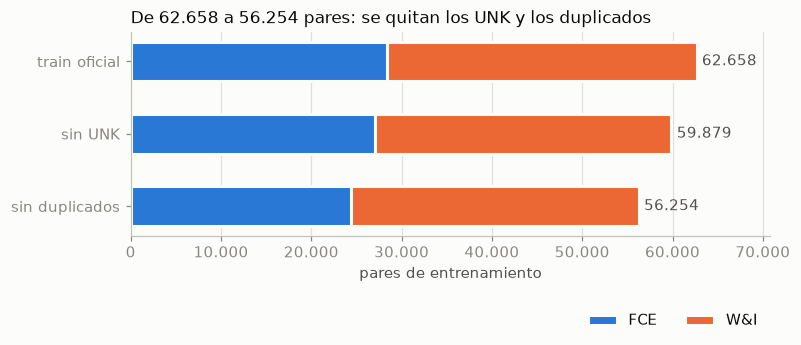

corpus,fce,wi,total
train oficial,28350,34308,62658
sin UNK,27082,32797,59879
sin duplicados,24442,31812,56254


In [11]:
train = preparar.pares_train(o)
etapas = {
    "train oficial": o[en_train],
    "sin UNK": sin_unk,
    "sin duplicados": train,
}
embudo = pd.DataFrame({e: df.corpus.value_counts() for e, df in etapas.items()}).T[["fce", "wi"]]
embudo["total"] = embudo.sum(axis=1)

fig, ax = plt.subplots(figsize=(7.5, 2.4))
izquierda = pd.Series(0, index=embudo.index)
for c in ["fce", "wi"]:
    ax.barh(embudo.index, embudo[c], left=izquierda, color=COLOR_CORPUS[c], height=0.55,
            edgecolor="#fcfcfb", linewidth=2, label=NOMBRE_CORPUS[c])
    izquierda += embudo[c]
for i, total in enumerate(embudo.total):
    ax.text(total + 600, i, f"{total:,}".replace(",", "."), va="center", color=TINTA_SECUNDARIA)
ax.invert_yaxis()
ax.set_xlim(0, embudo.total.max() * 1.13)
ax.grid(axis="y", visible=False)
ax.set_xlabel("pares de entrenamiento")
ax.set_title("De 62.658 a 56.254 pares: se quitan los UNK y los duplicados")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
ax.legend(loc="upper right", bbox_to_anchor=(1, -0.32), frameon=False, ncol=2)
fig.savefig(FIG / "13_embudo_preparacion.png")
plt.show()
embudo

## 5 · Conjuntos de evaluación

| Conjunto | Contenido | Uso |
|---|---|---|
| `dev_seleccion` | W&I dev + FCE dev **sin** hispanohablantes | elegir el checkpoint (F0.5 por época) |
| `fce_dev_es` | FCE dev, solo hispanohablantes | evaluar al usuario final, aparte |
| `fce_test` | FCE test completo | resultado final, una sola vez |
| `fce_test_es` | FCE test, solo hispanohablantes | evaluar al usuario final, aparte |

Los hispanohablantes de FCE dev salen de la selección: si el checkpoint se eligiera también con ellos, su F0.5 en dev saldría optimista. LOCNESS (nativos) no entra en ningún conjunto; solo sirvió de referencia en el análisis.

In [12]:
conjuntos = preparar.conjuntos_evaluacion(o)
pd.DataFrame([
    {"conjunto": n, "oraciones": len(df), "textos": df.texto.nunique(),
     "hispanohablantes": int(df.l1.eq("es").sum()), "ediciones": int(df.n_ediciones.sum()),
     "sin error (%)": round(100 * df.n_ediciones.eq(0).mean(), 1)}
    for n, df in conjuntos.items()
]).set_index("conjunto")

,oraciones,textos,hispanohablantes,ediciones,sin error (%)
conjunto,,,,,
dev_seleccion,5054,415,0,9234,32.7
fce_dev_es,533,44,533,977,37.1
fce_test,2695,194,224,4760,32.2
fce_test_es,224,20,224,638,29.5


## 6 · El BPE de BART: lo que entra a la red

BART no ve palabras sino **piezas BPE** (decisión T4: el tokenizador se usa sin cambios, no produce ningún `<unk>`). El espacio va pegado a la pieza que sigue (`Ġ`). Para entrenar, el tokenizador produce:

- `input_ids`: la oración original, que lee el codificador;
- `labels`: la oración corregida, que el decodificador debe generar pieza a pieza.

In [13]:
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore", message="IProgress not found")
from transformers import AutoTokenizer

tokenizador = AutoTokenizer.from_pretrained("facebook/bart-base")
LARGO_MAXIMO = 128

par = o.loc[EJEMPLO]
lote = tokenizador(par.original_texto, text_target=par.corregida_texto, max_length=LARGO_MAXIMO, truncation=True)
for nombre in ["input_ids", "labels"]:
    ids = lote[nombre]
    print(f"{nombre} ({len(ids)} piezas)")
    print("  ", " ".join(tokenizador.convert_ids_to_tokens(ids)))
    print("  ", ids, "\n")

input_ids (30 piezas)
   <s> As Ġyou Ġknow ĠI Ġam Ġin Ġcharge Ġfor Ġorganise Ġthe Ġconference Ġin Ġmy Ġcollege . ĠDo Ġnot Ġworry Ġif ĠRichard Ġdid Ġnot Ġleft Ġyou Ġall Ġthe Ġinformation . </s>
   [0, 1620, 47, 216, 38, 524, 11, 1427, 13, 23750, 5, 1019, 11, 127, 1564, 4, 1832, 45, 4022, 114, 2431, 222, 45, 314, 47, 70, 5, 335, 4, 2] 

labels (31 piezas)
   <s> As Ġyou Ġknow , ĠI Ġam Ġin Ġcharge Ġof Ġorganising Ġthe Ġconference Ġin Ġmy Ġcollege . ĠDo Ġnot Ġworry Ġif ĠRichard Ġdid Ġnot Ġleave Ġyou Ġall Ġthe Ġinformation . </s>
   [0, 1620, 47, 216, 6, 38, 524, 11, 1427, 9, 22821, 5, 1019, 11, 127, 1564, 4, 1832, 45, 4022, 114, 2431, 222, 45, 989, 47, 70, 5, 335, 4, 2] 



Las piezas corregidas (`Ġof`, `Ġorganising`, `Ġleave`, la coma) son las únicas que BART debe cambiar: el resto lo copia del original. Por eso la métrica es F0.5 sobre ediciones y no exactitud por pieza (decisión T2).

Con el largo máximo de 128 piezas (entrega 1), ¿cuántos pares del train final se recortan?

In [14]:
largos = pd.DataFrame({
    "original": [len(i) for i in tokenizador(train.original_texto.tolist())["input_ids"]],
    "corregida": [len(i) for i in tokenizador(train.corregida_texto.tolist())["input_ids"]],
})
pd.DataFrame({
    "mediana": largos.median(), "p99": largos.quantile(0.99), "máximo": largos.max(),
    f"> {LARGO_MAXIMO} (se recortan)": (largos > LARGO_MAXIMO).sum(),
}).astype(int)

,mediana,p99,máximo,> 128 (se recortan)
original,18,58,222,15
corregida,18,59,238,17


## 7 · Escribir los archivos

`preparar.escribir` deja todo en `datos/procesados/entrenamiento/` (fuera del repositorio, por la licencia de los corpus):

- `train.jsonl`: un par por línea, en texto natural;
- por cada conjunto de evaluación, `entrada.jsonl` (lo que recibe BART), `orig.txt` (tokens del M2) y `ref.m2` (la anotación oficial, con todos sus anotadores).

In [15]:
resumen = preparar.escribir(o, bloques, SALIDA)
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "train": {
    "pares": 56254,
    "excluidos_unk": 2779,
    "duplicados_quitados": 3625
  },
  "dev_seleccion": {
    "oraciones": 5054,
    "textos": 415
  },
  "fce_dev_es": {
    "oraciones": 533,
    "textos": 44
  },
  "fce_test": {
    "oraciones": 2695,
    "textos": 194
  },
  "fce_test_es": {
    "oraciones": 224,
    "textos": 20
  }
}


In [16]:
print((SALIDA / "train.jsonl").read_text(encoding="utf-8").splitlines()[5])
print(*sorted(str(p.relative_to(SALIDA)) for p in SALIDA.rglob("*") if p.is_file()), sep="\n")

{"id": 5, "original": "On the other hand, the theatre restaurant was closed because unknown reasons.", "corregida": "In addition, the theatre restaurant was closed for unknown reasons."}
dev_seleccion/entrada.jsonl
dev_seleccion/orig.txt
dev_seleccion/ref.m2
fce_dev_es/entrada.jsonl
fce_dev_es/orig.txt
fce_dev_es/ref.m2
fce_test/entrada.jsonl
fce_test/orig.txt
fce_test/ref.m2
fce_test_es/entrada.jsonl
fce_test_es/orig.txt
fce_test_es/ref.m2
resumen.json
train.jsonl


## 8 · Comprobar la cadena de evaluación

Antes de entrenar se comprueba que la evaluación funciona con dos extremos conocidos sobre `fce_test_es`:

- **copiar la entrada** (no corregir nada) debe dar F0.5 = 0: es la línea base que el modelo debe superar;
- **la corrección de referencia** debe acercarse al techo de 0,855 medido en el notebook 02 (P5): no llega a 1 porque ERRANT no siempre parte las ediciones igual que el anotador.

Es exactamente el procedimiento que se usará con la salida de BART.

In [17]:
def f05(carpeta, hipotesis):
    """F0.5 de ERRANT de una hipótesis (una oración tokenizada por línea) contra el ref.m2 del conjunto."""
    with tempfile.TemporaryDirectory() as tmp:
        hyp, hyp_m2 = Path(tmp) / "hyp.txt", Path(tmp) / "hyp.m2"
        hyp.write_text("\n".join(hipotesis) + "\n", encoding="utf-8")
        subprocess.run(["errant_parallel", "-orig", carpeta / "orig.txt", "-cor", hyp, "-out", hyp_m2],
                       check=True, capture_output=True)
        salida = subprocess.run(["errant_compare", "-hyp", hyp_m2, "-ref", carpeta / "ref.m2"],
                                check=True, capture_output=True, text=True).stdout
    tp, fp, fn, p, r, f = salida.split("\n")[3].split("\t")
    return {"TP": tp, "FP": fp, "FN": fn, "P": p, "R": r, "F0.5": f}

es_test = conjuntos["fce_test_es"]
carpeta = SALIDA / "fce_test_es"
pd.DataFrame({
    "copiar la entrada": f05(carpeta, es_test.original),
    "corrección de referencia": f05(carpeta, es_test.corregida),
}).T

,TP,FP,FN,P,R,F0.5
copiar la entrada,0,0,612,1.0,0.0,0.0
corrección de referencia,519,87,93,0.8564,0.848,0.8547


## Resumen

| Paso | Transformación | Resultado |
|---|---|---|
| 1 · Leer | M2 + JSON → oraciones con su L1 | 71.928 oraciones (FCE 33.236 + W&I+LOCNESS 38.692) |
| 2 · Aplicar ediciones | tokens + ediciones → oración corregida | un par original → corregida por oración |
| 3 · Destokenizar | `do n't` → `don't` | BART ve texto natural; ERRANT evalúa sobre tokens |
| 4 · Filtrar train | sin `UNK` (2.779), sin duplicados (3.625) | **56.254 pares** |
| 5 · Evaluación | hispanohablantes de dev fuera de la selección | `dev_seleccion` 5.054 · `fce_dev_es` 533 · `fce_test` 2.695 · `fce_test_es` 224 |
| 6 · BPE | texto → piezas de BART, máximo 128 | mediana 18 piezas; se recortan 15 originales y 17 corregidas (0,03 %) |
| 7 · Archivos | `train.jsonl` + `entrada.jsonl` / `orig.txt` / `ref.m2` | listos para `04_entrenamiento` |